# KAN-1 — Setup, carregamento e qualidade dos dados

Projeto CIN0144 · Tema 8: Praso — Previsão de Inadimplência.

Objetivo: carregar as tabelas de **clientes** (aplicação) e **pedidos** (comportamental), conferir as chaves e os formatos, checar a qualidade (tipos, nulos, duplicatas, valores fora do esperado, desbalanceamento) e gerar um dataset limpo e padronizado para as próximas etapas.

**Escopo da limpeza:** só o que não perde informação e não exige escolha de modelagem (tipos, datas e ordenação; nenhum registro é removido). Como representar faixas, criar flags ou preencher nulos fica com a engenharia de features (`src/features_aplicacao.py`, KAN-5, e `src/features_comportamentais.py`, KAN-7).

> Os CSVs ficam em `data/raw/` e **não vão para o GitHub** (termo de confidencialidade da Praso). Nos notebooks mostramos só agregados, nunca linhas de clientes.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src import dados

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)

## 1. Carregamento

In [2]:
clientes_raw, pedidos_raw = dados.carregar_brutos()
print("clientes:", clientes_raw.shape, "| pedidos:", pedidos_raw.shape)
print("colunas de clientes:", list(clientes_raw.columns))
print("colunas de pedidos:", list(pedidos_raw.columns))

clientes: (3000, 19) | pedidos: (1977, 5)
colunas de clientes: ['id_cliente', 'uf', 'municipio', 'segmento_cliente', 'natureza_juridica', 'fonte_cliente', 'cnae_codigo', 'capital_social', 'idade_cnpj', 'serasa_contagem_negativacoes', 'serasa_contagem_protestos', 'serasa_credores', 'serasa_socio_tem_negativacao', 'ifood_contagem_avaliacoes', 'ifood_faixa_preco', 'google_maps_avaliacao', 'google_maps_contagem_avaliacoes', 'google_maps_tem_website', 'inadimplente']
colunas de pedidos: ['id_pedido', 'id_cliente', 'valor', 'atraso', 'data_entrega']


## 2. Chaves, duplicatas e formatos

In [3]:
print("linhas duplicadas — clientes:", clientes_raw.duplicated().sum(), "| pedidos:", pedidos_raw.duplicated().sum())
dados.checar_chaves(clientes_raw, pedidos_raw)

linhas duplicadas — clientes: 0 | pedidos: 0


{'clientes_duplicados': 0,
 'pedidos_duplicados': 0,
 'pedidos_sem_cliente': 0,
 'clientes_com_pedidos': 664}

In [4]:
# Valores não nulos fora do formato esperado (faixas "(a, b]", CNAE "00.00-0-00", datas). 0 = tudo certo.
dados.checar_formatos(clientes_raw, pedidos_raw)

{'capital_social': 0,
 'idade_cnpj': 0,
 'ifood_contagem_avaliacoes': 0,
 'google_maps_avaliacao': 0,
 'google_maps_contagem_avaliacoes': 0,
 'valor': 0,
 'atraso': 0,
 'cnae_codigo': 0,
 'data_entrega': 0}

## 3. Tipos, nulos e cardinalidade

In [5]:
dados.relatorio_qualidade(clientes_raw)

,tipo,nulos,pct_nulos,valores_distintos
id_cliente,int64,0,0.0,3000
uf,str,0,0.0,1
municipio,str,0,0.0,36
segmento_cliente,str,0,0.0,21
natureza_juridica,str,0,0.0,5
fonte_cliente,str,0,0.0,5
cnae_codigo,str,0,0.0,153
capital_social,str,0,0.0,19
idade_cnpj,str,0,0.0,20
serasa_contagem_negativacoes,float64,0,0.0,36


In [6]:
dados.relatorio_qualidade(pedidos_raw)

,tipo,nulos,pct_nulos,valores_distintos
id_pedido,int64,0,0.0,1977
id_cliente,int64,0,0.0,664
valor,str,1,0.1,4
atraso,str,1,0.1,9
data_entrega,str,0,0.0,539


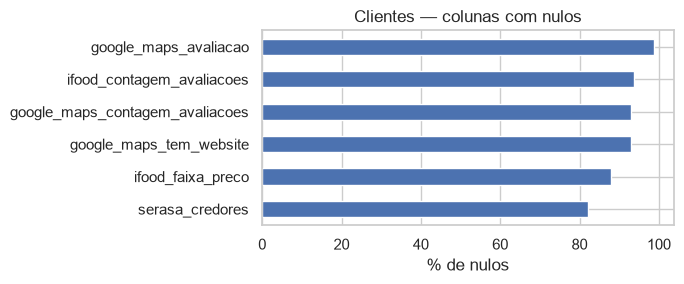

In [7]:
nulos = clientes_raw.isna().mean().mul(100).sort_values()
nulos = nulos[nulos > 0]
ax = nulos.plot.barh(figsize=(7, 3), color="#4C72B0")
ax.set_xlabel("% de nulos"); ax.set_title("Clientes — colunas com nulos")
plt.tight_layout(); plt.savefig(FIG / "kan1_nulos_clientes.png", dpi=150); plt.show()

## 4. Variável alvo (desbalanceamento)

inadimplente
adimplente      2060
inadimplente     940
Name: count, dtype: int64 

taxa de inadimplência: 31.3%


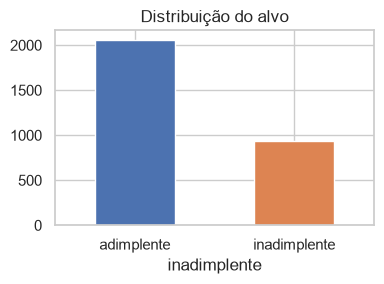

In [8]:
alvo = clientes_raw["inadimplente"].value_counts().rename({0.0: "adimplente", 1.0: "inadimplente"})
print(alvo, "\n\ntaxa de inadimplência: {:.1%}".format(clientes_raw["inadimplente"].mean()))
ax = alvo.plot.bar(figsize=(4, 3), color=["#4C72B0", "#DD8452"], rot=0)
ax.set_title("Distribuição do alvo"); plt.tight_layout(); plt.savefig(FIG / "kan1_alvo.png", dpi=150); plt.show()

## 5. Valores fora do esperado

In [9]:
for col in ["uf", "fonte_cliente", "natureza_juridica", "ifood_faixa_preco", "google_maps_tem_website"]:
    print(col, clientes_raw[col].value_counts(dropna=False).to_dict(), "\n")
clientes_raw[["serasa_contagem_negativacoes", "serasa_contagem_protestos"]].describe()

uf {'CE': 3000} 

fonte_cliente {'Fonte 1': 2055, 'Fonte 5': 736, 'Fonte 2': 200, 'Fonte 3': 7, 'Fonte 4': 2} 

natureza_juridica {'213-5 - Empresário (Individual)': 2249, '206-2 - Sociedade Empresária Limitada': 736, '230-5 - Empresa Individual de Responsabilidade Limitada (de Natureza Empresária)': 12, '224-0 - Sociedade Simples Limitada': 2, '205-4 - Sociedade Anônima Fechada': 1} 

ifood_faixa_preco {nan: 2637, '$': 284, '$$$': 34, '$$': 29, '$$$$': 13, '$$$$$': 3} 

google_maps_tem_website {nan: 2792, 1.0: 208} 



,serasa_contagem_negativacoes,serasa_contagem_protestos
count,3000.000000,3000.000000
mean,1.003000,0.263333
std,4.464635,1.936295
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,0.000000
75%,0.000000,0.000000
max,141.000000,79.000000


In [10]:
for col in ["valor", "atraso"]:
    print(col, pedidos_raw[col].value_counts(dropna=False).to_dict(), "\n")
print("período de entregas:", pedidos_raw["data_entrega"].min(), "a", pedidos_raw["data_entrega"].max())

valor {'(0, 500]': 1577, '(500, 1000]': 278, '(1000, 2000]': 97, '(2000, 10000000]': 24, nan: 1} 

atraso {'(0, 2]': 903, '(-100, 0]': 543, '(2, 4]': 255, '(4, 6]': 105, '(6, 10]': 74, '(10, 15]': 40, '(15, 30]': 28, '(30, 60]': 16, '(60, 10000000]': 12, nan: 1} 

período de entregas: 2022-04-25 a 2026-04-01


In [11]:
# Consistência entre colunas da mesma plataforma
gm_nota, gm_cont = clientes_raw["google_maps_avaliacao"].notna(), clientes_raw["google_maps_contagem_avaliacoes"].notna()
if_faixa, if_cont = clientes_raw["ifood_faixa_preco"].notna(), clientes_raw["ifood_contagem_avaliacoes"].notna()
n_credores = clientes_raw["serasa_credores"].fillna("").str.split(",").map(lambda l: len([x for x in l if x.strip()]))
print("Google Maps — com contagem:", gm_cont.sum(), "| com nota:", gm_nota.sum(), "| contagem sem nota:", (gm_cont & ~gm_nota).sum())
print("iFood — com faixa de preço:", if_faixa.sum(), "| com contagem:", if_cont.sum(), "| faixa sem contagem:", (if_faixa & ~if_cont).sum())
print("Credores — clientes com mais de 5 listados (a Praso diz 'até 5'):", (n_credores > 5).sum())

Google Maps — com contagem: 208 | com nota: 34 | contagem sem nota: 174
iFood — com faixa de preço: 363 | com contagem: 186 | faixa sem contagem: 177
Credores — clientes com mais de 5 listados (a Praso diz 'até 5'): 5


## 6. Limpeza

In [12]:
com_nulo = dados.pedidos_com_nulo(pedidos_raw)
print(f"{com_nulo.sum()} pedidos têm nulo em valor ou atraso (sem valor: {pedidos_raw['valor'].isna().sum()}, "
      f"sem atraso: {pedidos_raw['atraso'].isna().sum()}); a decisão fica com a KAN-7")

clientes, pedidos = dados.carregar_dados_limpos(salvar=True)
print("\nclientes:", clientes.shape, "| pedidos:", pedidos.shape)
print("nenhum pedido removido:", len(pedidos) == len(pedidos_raw))
print("mesmas colunas do CSV — clientes:", list(clientes.columns) == list(clientes_raw.columns),
      "| pedidos:", list(pedidos.columns) == list(pedidos_raw.columns))
print("nulos preservados — clientes:", clientes.isna().sum().equals(clientes_raw.isna().sum()),
      "| pedidos:", pedidos.isna().sum().equals(pedidos_raw.isna().sum()))
pd.DataFrame({"tipo_original": clientes_raw.dtypes.astype(str), "tipo_limpo": clientes.dtypes.astype(str)}).query("tipo_original != tipo_limpo")

2 pedidos têm nulo em valor ou atraso (sem valor: 1, sem atraso: 1); a decisão fica com a KAN-7

clientes: (3000, 19) | pedidos: (1977, 5)
nenhum pedido removido: True
mesmas colunas do CSV — clientes: True | pedidos: True
nulos preservados — clientes: True | pedidos: True


,tipo_original,tipo_limpo
capital_social,str,category
idade_cnpj,str,category
serasa_contagem_negativacoes,float64,int64
serasa_contagem_protestos,float64,int64
serasa_socio_tem_negativacao,float64,int64
ifood_contagem_avaliacoes,str,category
google_maps_avaliacao,str,category
google_maps_contagem_avaliacoes,str,category
inadimplente,float64,int64


In [13]:
pd.DataFrame({"tipo_original": pedidos_raw.dtypes.astype(str), "tipo_limpo": pedidos.dtypes.astype(str)}).query("tipo_original != tipo_limpo")

,tipo_original,tipo_limpo
valor,str,category
atraso,str,category
data_entrega,str,datetime64[us]


As faixas viram **categórica ordenada pelo limite inferior**, com as categorias fixadas na base inteira. O texto e os nulos não mudam. Como texto, elas se ordenariam alfabeticamente (`"(150, 250]"` depois de `"(1300, 1600]"`); como categórica, a ordem é a numérica e o código de cada faixa (`.cat.codes`) é o mesmo em qualquer subconjunto, por exemplo treino e teste.

> O CSV salvo em `data/processed/` perde o tipo categórico. Nos notebooks, carregue os dados com `dados.carregar_dados_limpos()`.

In [14]:
for col in dados.INTERVALOS_CLIENTES + dados.INTERVALOS_PEDIDOS:
    s = clientes[col] if col in clientes else pedidos[col]
    print(f"{col}: {len(s.cat.categories)} faixas, ordenada={s.cat.ordered} | {list(s.cat.categories[:3])} ... {s.cat.categories[-1]}")

def mesmo_texto(limpo, bruto, chave, colunas):
    a, b = limpo.set_index(chave).sort_index(), bruto.set_index(chave).sort_index()
    return all((a[col].astype(object).fillna("") == b[col].fillna("")).all() for col in colunas)

print("\ntexto preservado — clientes:", mesmo_texto(clientes, clientes_raw, "id_cliente", dados.INTERVALOS_CLIENTES),
      "| pedidos:", mesmo_texto(pedidos, pedidos_raw, "id_pedido", dados.INTERVALOS_PEDIDOS))

capital_social: 19 faixas, ordenada=True | ['(0, 1]', '(1, 200]', '(200, 1000]'] ... (10000000, 100000000000]
idade_cnpj: 20 faixas, ordenada=True | ['(0, 25]', '(25, 50]', '(50, 100]'] ... (8000, 25000]
ifood_contagem_avaliacoes: 11 faixas, ordenada=True | ['(0, 5]', '(5, 10]', '(10, 20]'] ... (1500, 2000]
google_maps_avaliacao: 5 faixas, ordenada=True | ['(0.0, 1.0]', '(1.0, 2.0]', '(2.0, 3.0]'] ... (4.5, 5.0]
google_maps_contagem_avaliacoes: 14 faixas, ordenada=True | ['(0, 5]', '(5, 10]', '(10, 20]'] ... (10000, 20000]
valor: 4 faixas, ordenada=True | ['(0, 500]', '(500, 1000]', '(1000, 2000]'] ... (2000, 10000000]
atraso: 9 faixas, ordenada=True | ['(-100, 0]', '(0, 2]', '(2, 4]'] ... (60, 10000000]

texto preservado — clientes: True | pedidos: True


## 7. Resumo

**Dados**
- `clientes`: 3.000 linhas × 19 colunas, uma por cliente (`id_cliente` único). Todos são do **CE** (36 municípios), então `uf` é constante.
- `pedidos`: 1.977 pedidos de **664 clientes** (22% da base), entregues entre 04/2022 e 04/2026. Todo pedido tem cliente correspondente.
- Nenhuma linha duplicada, nenhuma chave duplicada e nenhum valor fora do formato esperado.
- Alvo: 940 inadimplentes (**31,3%**) contra 2.060 adimplentes. É um desbalanceamento moderado: usar split estratificado e ROC-AUC.

**O que a limpeza fez** (`src/dados.py`)
- Converteu para `int` o alvo, as contagens da Serasa e `serasa_socio_tem_negativacao`, que vinham como float 0/1 sem nulos.
- Converteu `data_entrega` para data.
- Converteu as colunas em faixa para categórica ordenada pelo limite inferior, com as categorias fixadas na base inteira. O texto não muda.
- Não removeu nenhum pedido: 2 pedidos têm nulo em `valor` ou `atraso`; a decisão fica com a KAN-7.
- Ordenou os pedidos por cliente e data.
- As colunas são as mesmas do CSV, e os nulos continuam como vieram.

**Observações de qualidade** (para quem faz as features decidir)
- `capital_social`, `idade_cnpj`, as contagens e a nota de iFood/Google Maps e, nos pedidos, `valor` e `atraso` vêm em **faixas** (`"(150, 250]"`). O dicionário da Praso descreve `atraso` como número de dias. Nos pedidos, `"(-100, 0]"` significa sem atraso. A última faixa tem teto artificial, ex: `"(60, 10000000]"`.
- `google_maps_tem_website` só tem 1 ou nulo, e o nulo junta "não está no Maps" com "está, mas não tem site".
- A nota do Google Maps existe para só 34 clientes, contra 208 com contagem de avaliações. Há 177 clientes com faixa de preço do iFood e sem contagem.
- `serasa_credores` é nulo em 82% dos casos, e 5 clientes têm mais de 5 credores listados.
- As Fontes 3 e 4 têm 7 e 2 clientes. Negativações e protestos têm cauda longa (máx. 141 e 79).

**Perguntas em aberto** (levar à Praso ou ao professor)
1. **Data de referência:** a tabela de clientes não tem data de cadastro nem a data em que a inadimplência foi observada. Sem isso, a KAN-7 não consegue cortar os pedidos no tempo.
2. **Alvo sem pedidos:** 78% dos clientes não têm nenhum pedido, mas têm `inadimplente` preenchido. O que significa inadimplência para quem não comprou?
3. **Consistência entre colunas:** por que a nota do Google Maps aparece para tão poucos clientes com avaliações, e por que há faixa de preço do iFood sem contagem?

**Saídas**: `data/processed/clientes_limpo.csv` e `pedidos_limpo.csv` (locais, fora do git), além dos gráficos em `reports/figures/`. Esses CSVs perdem o tipo categórico das faixas; o caminho certo é `dados.carregar_dados_limpos()`.